# BNDES non-automatic financing operations — extract, clean, validate, fit (br-bndes-operacoes-financiamento, 2026-09-01)

Source: BNDES open data, *Operações de Financiamento* → resource *Operações não automáticas* (ODbL 1.0), snapshot dated 1 September 2026, held in `sample/` (gitignored; re-download steps in the review README).
Review README: `../../README.md` · Need: `dataset-discovery/needs/2026-09-br-finance-pathways-review`.
Purpose: turn the README parsing notes into one typed, source-faithful subcredit table in `data/`, prove it with assertions, and answer only the fit questions the need raises. Charts render inline and are not saved. Restart-and-run-all must pass before commit.

In [1]:
import hashlib, os, re, unicodedata
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Parameters
RAW_PATH = "sample/operacoes-financiamento-operacoes-nao-automaticas.csv"
RAW_MD5_PUBLISHED = "b0b8902e33d3057403a6507ab0f4e7ab"      # BNDES resource metadata, checked 2026-09-24
RELEASE_DATE = "2026-09-01"
DATA_DIR = "data"
EXPORT_PATH = f"{DATA_DIR}/br_bndes_operacoes_financiamento_subcredits.csv.gz"
REPORT_APPROVALS_PATH = "sample/bndes_fundoclima_relatorios.tsv"
TRANSLATIONS_PATH = f"{DATA_DIR}/br_bndes_operacoes_financiamento_translations_en.csv"
FUNDO_CLIMA_INSTRUMENT = "PROGRAMA FUNDO CLIMA"

pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True})
BLUE, ORANGE, GREY = "#1f5f8b", "#c8702a", "#b8b8b8"

raw_bytes = open(RAW_PATH, "rb").read()
raw_md5 = hashlib.md5(raw_bytes).hexdigest()
print("raw MB:", round(len(raw_bytes) / 1e6, 2), "| MD5 matches publisher:", raw_md5 == RAW_MD5_PUBLISHED)

raw MB: 20.01 | MD5 matches publisher: True


## 1. Load raw — zero transformations

Parsing note (README): CP1252, semicolon-delimited, quoted header, 34 fields, no blank cells. Everything is read as text so identifiers, sentinels and decimal commas survive untouched. Client data are legal-entity names and CNPJs, not personal data, so no columns are dropped at load; §4 asserts that no CPF-shaped identifier is present.

In [2]:
assert raw_md5 == RAW_MD5_PUBLISHED, "raw file differs from the publisher's resource; re-download before running"
raw = pd.read_csv(RAW_PATH, sep=";", encoding="cp1252", dtype=str, keep_default_na=False, na_filter=False)
raw.insert(0, "raw_row_id", np.arange(1, len(raw) + 1))   # 1-based data-line number; the export has no subcredit id
print(raw.shape)
raw.head(3)

(23815, 35)


,raw_row_id,cliente,cnpj,descricao_do_projeto,uf,municipio,municipio_codigo,numero_do_contrato,data_da_contratacao,valor_contratado_reais,...,subsetor_cnae_nome,setor_bndes,subsetor_bndes,porte_do_cliente,natureza_do_cliente,instituicao_financeira_credenciada,cnpj_da_instituicao_financeira_credenciada,tipo_de_garantia,tipo_de_excepcionalidade,situacao_do_contrato
0,1,MUNICIPIO DE RIBEIRAO PRETO,56.024.581/0001-56,PROGRAMA DE MODERNIZACAO DA ADMINISTRACAO TRIBUTARIA E D...,SP,RIBEIRAO PRETO,3543402,1247021,2002-01-02,"9090000,0",...,ADMINISTRACAO PUBLICA EM GERAL ...,COMERCIO/SERVICOS,COMÉRCIO E SERVIÇOS,GRANDE,ADMINISTRAÇÃO PÚBLICA DIRETA - GOVERNO MUNICIPAL,----------,----------,"OUTRA, DE NATUREZA ESPECÍFICA OU MISTA",----------,LIQUIDADO
1,2,INSTITUTO DE DESENVOLVIMENTO SUSTENTAVEL DO BAIXO SUL D,02.275.306/0001-86,PROJETO DIREITO E CIDADANIA; PROJETO DEMONSTRATIVO DA CA...,BA,ITUBERA,2917300,1247221,2002-01-03,"706600,0",...,ATIV ATENCAO A SAUDE HUMANA INTEGR C/ASSIST SOC PREST RE...,COMERCIO/SERVICOS,COMÉRCIO E SERVIÇOS,MICRO,PRIVADA,----------,----------,NÃO SE APLICA,----------,LIQUIDADO
2,3,INSTITUTO DE DESENVOLVIMENTO SUSTENTAVEL DO BAIXO SUL D,02.275.306/0001-86,PROJETO DIREITO E CIDADANIA; PROJETO DEMONSTRATIVO DA CA...,BA,ITUBERA,2917300,1247221,2002-01-03,"75691,59",...,ATIV ATENCAO A SAUDE HUMANA INTEGR C/ASSIST SOC PREST RE...,COMERCIO/SERVICOS,COMÉRCIO E SERVIÇOS,MICRO,PRIVADA,----------,----------,NÃO SE APLICA,----------,LIQUIDADO


## 2. Clean — one parsing note per block

### 2.1 Live header, not the dictionary
Parsing note: the 2020 dictionary lists 35 fields ending in a derived `Ano`; the live CSV has 34 and omits it. Test the live header, then derive the contract year from `data_da_contratacao`.

In [3]:
EXPECTED_COLUMNS = ["cliente", "cnpj", "descricao_do_projeto", "uf", "municipio", "municipio_codigo",
    "numero_do_contrato", "data_da_contratacao", "valor_contratado_reais", "valor_desembolsado_reais",
    "fonte_de_recurso_desembolsos", "custo_financeiro", "juros", "prazo_carencia_meses", "prazo_amortizacao_meses",
    "modalidade_de_apoio", "forma_de_apoio", "produto", "instrumento_financeiro", "inovacao", "area_operacional",
    "setor_cnae", "subsetor_cnae_agrupado", "subsetor_cnae_codigo", "subsetor_cnae_nome", "setor_bndes",
    "subsetor_bndes", "porte_do_cliente", "natureza_do_cliente", "instituicao_financeira_credenciada",
    "cnpj_da_instituicao_financeira_credenciada", "tipo_de_garantia", "tipo_de_excepcionalidade", "situacao_do_contrato"]
assert list(raw.columns[1:]) == EXPECTED_COLUMNS, "live header changed; update parsing notes first"
assert "ano" not in raw.columns
subcredits = raw.copy()
print("header OK:", len(EXPECTED_COLUMNS), "source fields")

header OK: 34 source fields


### 2.2 Outer whitespace; cleaned project description beside the raw text
Parsing note: descriptions, `setor_cnae`, `subsetor_cnae_nome` and `natureza_do_cliente` carry padding. Trim outer whitespace on every text field; keep `descricao_do_projeto_raw` and add a cleaned description with internal runs of spaces collapsed.

In [4]:
TEXT_COLUMNS = [c for c in EXPECTED_COLUMNS]
padded_before = {c: int((subcredits[c] != subcredits[c].str.strip()).sum()) for c in TEXT_COLUMNS}
subcredits["descricao_do_projeto_raw"] = raw["descricao_do_projeto"]
for c in TEXT_COLUMNS:
    subcredits[c] = subcredits[c].str.strip()
subcredits["descricao_do_projeto"] = subcredits["descricao_do_projeto"].str.replace(r"\s+", " ", regex=True)
pd.Series({k: v for k, v in padded_before.items() if v}, name="rows_with_outer_whitespace").to_frame()

,rows_with_outer_whitespace
descricao_do_projeto,22375
setor_cnae,23815
subsetor_cnae_nome,23548
natureza_do_cliente,21818
tipo_de_garantia,3


### 2.3 Field-specific sentinels to nulls
Parsing note: `----------` marks an empty intermediary or exception field; `-` marks an unknown funding source or contract status. Only those fields are nulled, and only for the exact sentinel.

In [5]:
SENTINELS = {
    "instituicao_financeira_credenciada": "----------",
    "cnpj_da_instituicao_financeira_credenciada": "----------",
    "tipo_de_excepcionalidade": "----------",
    "fonte_de_recurso_desembolsos": "-",
    "situacao_do_contrato": "-",
}
sentinel_counts = {}
for col, token in SENTINELS.items():
    is_sentinel = subcredits[col].eq(token)
    sentinel_counts[col] = int(is_sentinel.sum())
    subcredits.loc[is_sentinel, col] = None
pd.Series(sentinel_counts, name="sentinel_rows_nulled").to_frame()

,sentinel_rows_nulled
instituicao_financeira_credenciada,19745
cnpj_da_instituicao_financeira_credenciada,19745
tipo_de_excepcionalidade,23576
fonte_de_recurso_desembolsos,748
situacao_do_contrato,268


### 2.4 Identifiers stay text
Parsing note: the dictionary types CNPJ, municipality code and contract number as integers, but the CSV carries formatted CNPJs and sentinel codes. Keep every identifier as a string and check its shape.

In [6]:
ID_COLUMNS = ["cnpj", "numero_do_contrato", "municipio_codigo", "subsetor_cnae_codigo", "cnpj_da_instituicao_financeira_credenciada"]
id_shapes = {c: subcredits[c].dropna().str.replace(r"\d", "9", regex=True).value_counts().head(3).to_dict() for c in ID_COLUMNS}
assert subcredits["cnpj"].str.fullmatch(r"\d{2}\.\d{3}\.\d{3}/\d{4}-\d{2}").all()
assert subcredits["numero_do_contrato"].str.fullmatch(r"\d+").all()
pd.Series(id_shapes, name="most_common_shapes").to_frame()

,most_common_shapes
cnpj,{'99.999.999/9999-99': 23815}
numero_do_contrato,"{'99999999': 16023, '9999999': 7774, '999999': 18}"
municipio_codigo,"{'9999999': 19001, '9': 4814}"
subsetor_cnae_codigo,"{'C9999999': 8231, 'D9999999': 5232, 'H9999999': 3049}"
cnpj_da_instituicao_financeira_credenciada,{'99999999999999': 4070}


### 2.5 Decimal-comma amounts as exact decimals
Parsing note: contracted value, disbursed value and `juros` use a decimal comma, no thousands separator, and variable precision. Normalise to dot-decimal text (exported exactly as published) and hold `Decimal` objects for validation sums. `juros` keeps its source name because the dictionary does not state its unit.

In [7]:
DECIMAL_COLUMNS = ["valor_contratado_reais", "valor_desembolsado_reais", "juros"]
for c in DECIMAL_COLUMNS:
    assert subcredits[c].str.fullmatch(r"\d+(,\d+)?").all(), f"unexpected number format in {c}"
    subcredits[c] = subcredits[c].str.replace(",", ".", regex=False)
contracted_dec = subcredits["valor_contratado_reais"].map(Decimal)
disbursed_dec = subcredits["valor_desembolsado_reais"].map(Decimal)
for c in ["prazo_carencia_meses", "prazo_amortizacao_meses"]:
    subcredits[c] = subcredits[c].astype(int)
print("contracted total (R$, exact):", f"{sum(contracted_dec):,.2f}", "| max decimals:",
      subcredits["valor_contratado_reais"].str.split(".").str[1].str.len().max())

contracted total (R$, exact): 1,242,719,143,348.93 | max decimals: 8


### 2.6 ISO contract dates and derived contract year
Parsing note: `data_da_contratacao` is ISO `YYYY-MM-DD` throughout. Parse strictly; derive `contract_year` in place of the dictionary's missing `Ano`.

In [8]:
subcredits["data_da_contratacao"] = pd.to_datetime(subcredits["data_da_contratacao"], format="%Y-%m-%d", errors="raise").dt.date
subcredits["contract_year"] = pd.to_datetime(subcredits["data_da_contratacao"]).dt.year
subcredits["contract_year"].agg(["min", "max", "nunique"]).to_frame().T

,min,max,nunique
contract_year,2002,2026,25


### 2.7 Geography validity flags
Parsing note: valid Brazilian municipality codes are seven digits; `0` and `9999999` are non-municipal sentinels; `IE` is not a Brazilian federative unit. Flag both, and null the sentinel code and its `SEM MUNICÍPIO` / `DIVERSOS` label so no join can use them.

In [9]:
BRAZIL_UFS = {"AC","AL","AP","AM","BA","CE","DF","ES","GO","MA","MT","MS","MG","PA","PB","PR","PE","PI","RJ","RN","RS","RO","RR","SC","SP","SE","TO"}
subcredits["is_brazilian_uf"] = subcredits["uf"].isin(BRAZIL_UFS)
subcredits["is_brazilian_municipality"] = subcredits["municipio_codigo"].str.fullmatch(r"\d{7}") & subcredits["municipio_codigo"].ne("9999999") & subcredits["is_brazilian_uf"]
subcredits.loc[~subcredits["is_brazilian_municipality"], ["municipio_codigo", "municipio"]] = None
pd.crosstab(subcredits["is_brazilian_uf"], subcredits["is_brazilian_municipality"], margins=True)

is_brazilian_municipality,False,True,All
is_brazilian_uf,,,
False,2599,0,2599
True,5167,16049,21216
All,7766,16049,23815


### 2.8 Identical rows: flag, keep, and mark the sensitivity extras
Parsing note: identical published rows cannot be told apart from accidental duplicates because the export has no subcredit id. Keep every row; give each identical group an id; mark all but the first member as `is_identical_extra` so a sensitivity total can exclude them.

In [10]:
source_cols = EXPECTED_COLUMNS
group_key = raw[source_cols].astype(str).agg("\x1f".join, axis=1)
is_in_group = group_key.duplicated(keep=False)
subcredits["identical_group_id"] = None
subcredits.loc[is_in_group, "identical_group_id"] = group_key[is_in_group].map(lambda k: hashlib.sha1(k.encode()).hexdigest()[:12])
subcredits["is_identical_extra"] = group_key.duplicated(keep="first")
pd.Series({"rows_in_identical_groups": int(is_in_group.sum()),
           "identical_groups": subcredits["identical_group_id"].nunique(),
           "extra_copies": int(subcredits["is_identical_extra"].sum())}).to_frame("count")

,count
rows_in_identical_groups,654
identical_groups,277
extra_copies,377


### 2.9 English values from the translation lookup
Parsing note: descriptive and categorical fields are in Portuguese. English values come from the committed lookup `data/br_bndes_operacoes_financiamento_translations_en.csv` (one row per source field and distinct Portuguese value), joined here without editing either side. Names of clients, places and financial institutions are proper nouns and are not translated. `inovacao` (`SIM`/`NÃO`) becomes a boolean.

In [11]:
translations = pd.read_csv(TRANSLATIONS_PATH, dtype=str, keep_default_na=False)
assert not translations.duplicated(["source_field", "value_pt"]).any() and translations["value_en"].str.strip().ne("").all()
TRANSLATED_FIELDS = sorted(translations["source_field"].unique())
coverage = {}
for field in TRANSLATED_FIELDS:
    lookup = translations[translations["source_field"].eq(field)].set_index("value_pt")["value_en"]
    present = set(subcredits[field].dropna())
    assert present == set(lookup.index), f"translation lookup out of step with source for {field}"
    subcredits[f"{field}_en"] = subcredits[field].map(lookup)
    coverage[field] = len(lookup)
assert set(subcredits["inovacao"]) == {"SIM", "NÃO"}
subcredits["is_innovation"] = subcredits["inovacao"].eq("SIM")
pd.Series(coverage, name="distinct_values_translated").to_frame()

,distinct_values_translated
area_operacional,13
custo_financeiro,30
descricao_do_projeto,6594
fonte_de_recurso_desembolsos,103
forma_de_apoio,2
instrumento_financeiro,188
modalidade_de_apoio,2
natureza_do_cliente,5
porte_do_cliente,4
produto,17


## 3. Contract rollup (in memory)

The publisher-defined contract total is the sum of its contracted subcredits. It is built here for validation and fit only; the export stays at subcredit grain.

In [12]:
place_raw = raw["uf"] + "|" + raw["municipio"] + "|" + raw["municipio_codigo"]           # as published, before nulling
description_trimmed = raw["descricao_do_projeto"].str.strip()
contracts = (subcredits.assign(contracted=contracted_dec, disbursed=disbursed_dec, place_raw=place_raw, description_trimmed=description_trimmed,
                               fundo_clima_contracted=np.where(subcredits["instrumento_financeiro"].eq(FUNDO_CLIMA_INSTRUMENT), contracted_dec, Decimal(0)))
    .groupby("numero_do_contrato")
    .agg(n_subcredits=("raw_row_id", "size"), contracted=("contracted", "sum"), disbursed=("disbursed", "sum"),
         fundo_clima_contracted=("fundo_clima_contracted", "sum"), first_date=("data_da_contratacao", "min"),
         n_clients=("cnpj", "nunique"), n_dates=("data_da_contratacao", "nunique"),
         n_descriptions=("description_trimmed", "nunique"), n_places=("place_raw", "nunique")))
contracts.describe(include="all").loc[["count", "max"], ["n_subcredits", "n_clients", "n_dates", "n_descriptions", "n_places"]]

,n_subcredits,n_clients,n_dates,n_descriptions,n_places
count,8388.0,8388.0,8388.0,8388.0,8388.0
max,99.0,18.0,32.0,14.0,26.0


## 4. Validate — assertions; nothing is exported if any fail

Structural checks are hard failures. The two documented source-side behaviours (identical rows; disbursed above contracted) are asserted as named exceptions at their profiled size, so a change in either stops the run.

In [13]:
# Structure and counts (README data profile)
assert len(subcredits) == 23_815 and subcredits["raw_row_id"].is_unique
assert subcredits["numero_do_contrato"].nunique() == 8_388
assert (contracts["n_subcredits"] > 1).sum() == 4_188 and contracts["n_subcredits"].max() == 99
assert (contracts["n_clients"] > 1).sum() == 172 and (contracts["n_dates"] > 1).sum() == 367
assert (contracts["n_descriptions"] > 1).sum() == 122 and (contracts["n_places"] > 1).sum() == 249
assert subcredits["modalidade_de_apoio"].value_counts().to_dict() == {"REEMBOLSÁVEL": 22_207, "NÃO REEMBOLSÁVEL": 1_608}
assert subcredits["natureza_do_cliente"].eq("PRIVADA").sum() == 21_818
assert subcredits["situacao_do_contrato"].value_counts(dropna=False).to_dict() == {"LIQUIDADO": 14_139, "ATIVO": 9_408, None: 268}
assert subcredits["municipio_codigo"].nunique() == 1_140 and subcredits["is_brazilian_municipality"].sum() == 16_049
# Rows without a usable municipality: 2,599 IE rows + 5,167 Brazilian-UF rows (3,066 code 0, 1,958 code 9999999
# labelled SEM MUNICÍPIO, 143 DIVERSOS). The README's earlier 5,619 missed the 9999999 rows in Brazilian UFs.
assert (subcredits["uf"].eq("IE")).sum() == 2_599
assert (~subcredits["is_brazilian_municipality"] & subcredits["is_brazilian_uf"]).sum() == 5_167
assert (raw["municipio_codigo"].eq("9999999") & raw["uf"].ne("IE")).sum() == 2_101

# Dates within the release
assert str(subcredits["data_da_contratacao"].min()) == "2002-01-02" and str(subcredits["data_da_contratacao"].max()) == "2026-07-31"
assert subcredits["data_da_contratacao"].max() <= pd.Timestamp(RELEASE_DATE).date()

# Amounts: non-negative, no blanks, profiled range
assert min(contracted_dec) == Decimal("0.55") and max(contracted_dec) == Decimal("9889997969.99")
assert min(disbursed_dec) >= 0 and (disbursed_dec == 0).sum() == 1_340

# Named source-side exceptions (documented, not absorbed)
assert int(subcredits["is_identical_extra"].sum()) == 377 and subcredits["identical_group_id"].nunique() == 277, "identical-row exception changed size"
assert (disbursed_dec > contracted_dec).sum() == 6_090 and (contracts["disbursed"] > contracts["contracted"]).sum() == 2_021, "indexation exception changed size"

# Spot-checks against published Fundo Clima approvals (BNDES annual reports)
for contract, fc_value, total in [("24203191", "250000000", "622606000"), ("24203391", "150000000", "150000000"),
                                  ("25203161", "80000000", "120000000"), ("25204501", "100000000", "250000000")]:
    row = contracts.loc[contract]
    assert row["fundo_clima_contracted"] == Decimal(fc_value) and row["contracted"] == Decimal(total), contract

# No personal identifiers: every client id is a CNPJ; no CPF-shaped number in names
assert subcredits["cnpj"].str.len().eq(18).all()
assert not subcredits["cliente"].str.contains(r"\d{3}\.?\d{3}\.?\d{3}-?\d{2}").any()

# No sentinel or IE code can reach a municipality join
assert not subcredits.loc[subcredits["is_brazilian_municipality"], "municipio_codigo"].isin(["0", "9999999"]).any()
assert set(subcredits.loc[subcredits["is_brazilian_municipality"], "uf"]) <= BRAZIL_UFS
print("ALL ASSERTIONS PASSED")

ALL ASSERTIONS PASSED


## 5. Export — one typed subcredit table to `data/`

Columns get English names. Each translated field carries the English value under the English name and the Portuguese source value under `<name>_pt`; proper nouns and identifiers carry one column. The rename map printed below is the schema. Amounts are written as exact dot-decimal text. Public use of this file is a derivative database under ODbL (see README licence).

In [14]:
# English column name <- working column. Translated fields: English value in the English name, Portuguese source value in <name>_pt.
EXPORT_SCHEMA = {
    "raw_row_id": "raw_row_id",
    "contract_number": "numero_do_contrato",
    "contract_date": "data_da_contratacao",
    "contract_year": "contract_year",
    "client_name": "cliente",
    "client_cnpj": "cnpj",
    "client_nature": "natureza_do_cliente_en", "client_nature_pt": "natureza_do_cliente",
    "client_size": "porte_do_cliente_en", "client_size_pt": "porte_do_cliente",
    "project_description": "descricao_do_projeto_en", "project_description_pt": "descricao_do_projeto",
    "project_description_pt_raw": "descricao_do_projeto_raw",
    "state_code": "uf",
    "municipality_name": "municipio",
    "municipality_ibge_code": "municipio_codigo",
    "is_brazilian_state": "is_brazilian_uf",
    "is_brazilian_municipality": "is_brazilian_municipality",
    "contracted_amount_brl": "valor_contratado_reais",
    "disbursed_amount_brl": "valor_desembolsado_reais",
    "support_modality": "modalidade_de_apoio_en", "support_modality_pt": "modalidade_de_apoio",
    "support_channel": "forma_de_apoio_en", "support_channel_pt": "forma_de_apoio",
    "product": "produto_en", "product_pt": "produto",
    "financing_instrument": "instrumento_financeiro_en", "financing_instrument_pt": "instrumento_financeiro",
    "disbursement_funding_source": "fonte_de_recurso_desembolsos_en", "disbursement_funding_source_pt": "fonte_de_recurso_desembolsos",
    "financial_cost_index": "custo_financeiro_en", "financial_cost_index_pt": "custo_financeiro",
    "interest_rate": "juros",
    "grace_period_months": "prazo_carencia_meses",
    "amortization_period_months": "prazo_amortizacao_meses",
    "guarantee_type": "tipo_de_garantia_en", "guarantee_type_pt": "tipo_de_garantia",
    "exception_type": "tipo_de_excepcionalidade_en", "exception_type_pt": "tipo_de_excepcionalidade",
    "contract_status": "situacao_do_contrato_en", "contract_status_pt": "situacao_do_contrato",
    "is_innovation": "is_innovation",
    "accredited_financial_institution": "instituicao_financeira_credenciada",
    "accredited_financial_institution_cnpj": "cnpj_da_instituicao_financeira_credenciada",
    "bndes_operational_area": "area_operacional_en", "bndes_operational_area_pt": "area_operacional",
    "bndes_sector": "setor_bndes_en", "bndes_sector_pt": "setor_bndes",
    "bndes_subsector": "subsetor_bndes_en", "bndes_subsector_pt": "subsetor_bndes",
    "cnae_sector": "setor_cnae_en", "cnae_sector_pt": "setor_cnae",
    "cnae_subsector_group": "subsetor_cnae_agrupado_en", "cnae_subsector_group_pt": "subsetor_cnae_agrupado",
    "cnae_subsector_code": "subsetor_cnae_codigo",
    "cnae_subsector_name": "subsetor_cnae_nome_en", "cnae_subsector_name_pt": "subsetor_cnae_nome",
    "identical_group_id": "identical_group_id",
    "is_identical_extra": "is_identical_extra",
}
# every source field is carried, and every translated field has both languages
carried = set(EXPORT_SCHEMA.values())
assert set(EXPECTED_COLUMNS) - carried == {"inovacao"}
assert all(f in carried and f"{f}_en" in carried for f in TRANSLATED_FIELDS)
export = subcredits[list(EXPORT_SCHEMA.values())].set_axis(list(EXPORT_SCHEMA), axis=1)
os.makedirs(DATA_DIR, exist_ok=True)
export.to_csv(EXPORT_PATH, index=False, encoding="utf-8", compression={"method": "gzip", "mtime": 0})
check = pd.read_csv(EXPORT_PATH, dtype=str, keep_default_na=False)
assert len(check) == len(subcredits) and list(check.columns) == list(EXPORT_SCHEMA)
assert sum(check["contracted_amount_brl"].map(Decimal)) == sum(contracted_dec)
print(EXPORT_PATH, "|", round(os.path.getsize(EXPORT_PATH) / 1e6, 1), "MB | SHA-256",
      hashlib.sha256(open(EXPORT_PATH, "rb").read()).hexdigest()[:16])
pd.DataFrame({"english_column": list(EXPORT_SCHEMA), "from_working_column": list(EXPORT_SCHEMA.values())})

data/br_bndes_operacoes_financiamento_subcredits.csv.gz | 3.2 MB | SHA-256 0169b3595ad659ae


,english_column,from_working_column
0,raw_row_id,raw_row_id
1,contract_number,numero_do_contrato
2,contract_date,data_da_contratacao
3,contract_year,contract_year
4,client_name,cliente
5,client_cnpj,cnpj
6,client_nature,natureza_do_cliente_en
7,client_nature_pt,natureza_do_cliente
8,client_size,porte_do_cliente_en
9,client_size_pt,porte_do_cliente


## 6. Visualise and fit

Charts show the portfolio shape the review cites. Fit cells answer only the three questions the need raises: does the table carry the must-have evidence fields; do the 23 annual-report Fundo Clima approvals already in the compile appear as contracts; and which BNDES routes public borrowers have actually used.

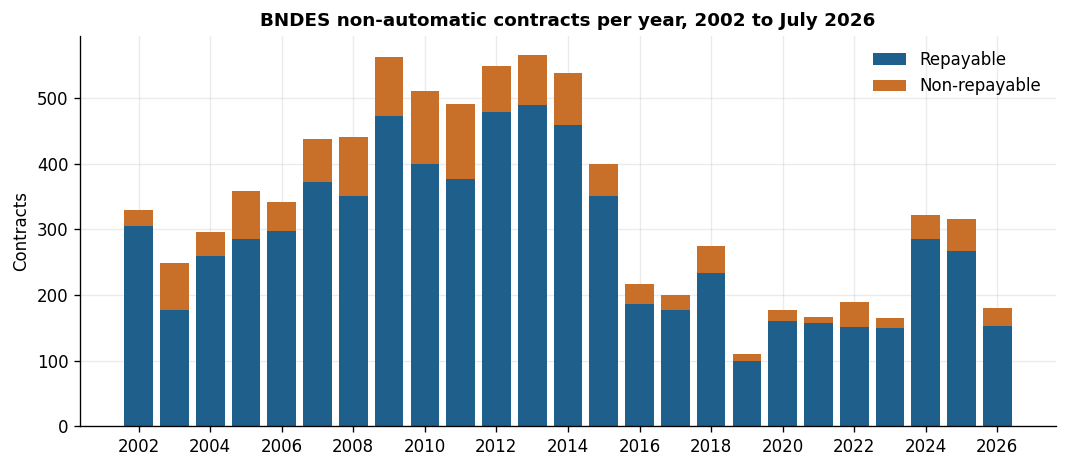

In [15]:
# 6.1 Contracts per year by support modality (contract counted in the year of its first subcredit)
contract_modality = subcredits.groupby("numero_do_contrato").agg(year=("contract_year", "min"),
    modality=("modalidade_de_apoio", lambda s: "Non-repayable" if s.eq("NÃO REEMBOLSÁVEL").all() else "Repayable"))
by_year = contract_modality.pivot_table(index="year", columns="modality", aggfunc="size", fill_value=0)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_year.index, by_year["Repayable"], color=BLUE, label="Repayable")
ax.bar(by_year.index, by_year["Non-repayable"], bottom=by_year["Repayable"], color=ORANGE, label="Non-repayable")
ax.set_title("BNDES non-automatic contracts per year, 2002 to July 2026"); ax.set_ylabel("Contracts"); ax.set_xticks(by_year.index[::2])
ax.legend(frameon=False); fig.tight_layout(); plt.show()

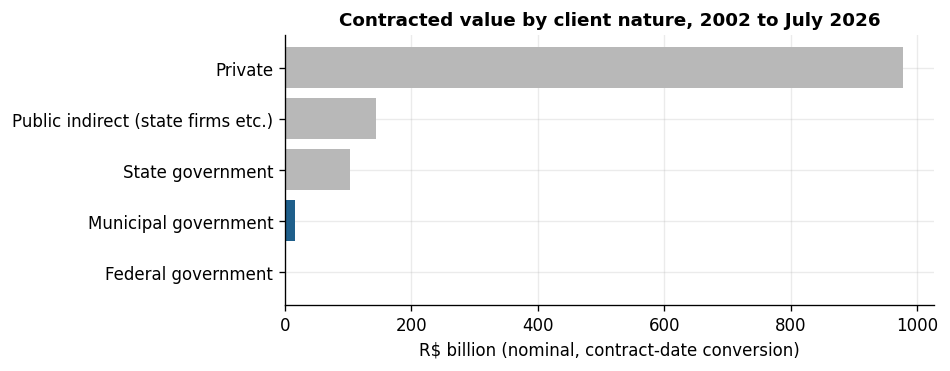

,contracted_brl_bn
natureza_do_cliente,
ADMINISTRAÇÃO PÚBLICA DIRETA - GOVERNO FEDERAL,0.8
ADMINISTRAÇÃO PÚBLICA DIRETA - GOVERNO MUNICIPAL,16.5
ADMINISTRAÇÃO PÚBLICA DIRETA - GOVERNO ESTADUAL,103.2
PÚBLICA INDIRETA,144.3
PRIVADA,977.9


In [16]:
# 6.2 Who borrows: contracted value by client nature (R$ billion, source-faithful subcredit sum)
value_by_nature = (subcredits.assign(v=subcredits["valor_contratado_reais"].astype(float))
                   .groupby("natureza_do_cliente")["v"].sum().div(1e9).sort_values())
labels = {"PRIVADA": "Private", "PÚBLICA INDIRETA": "Public indirect (state firms etc.)",
          "ADMINISTRAÇÃO PÚBLICA DIRETA - GOVERNO ESTADUAL": "State government",
          "ADMINISTRAÇÃO PÚBLICA DIRETA - GOVERNO MUNICIPAL": "Municipal government",
          "ADMINISTRAÇÃO PÚBLICA DIRETA - GOVERNO FEDERAL": "Federal government"}
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh([labels[i] for i in value_by_nature.index], value_by_nature.values, color=[BLUE if "Municipal" in labels[i] else GREY for i in value_by_nature.index])
ax.set_title("Contracted value by client nature, 2002 to July 2026"); ax.set_xlabel("R$ billion (nominal, contract-date conversion)")
fig.tight_layout(); plt.show()
value_by_nature.round(1).rename("contracted_brl_bn").to_frame()

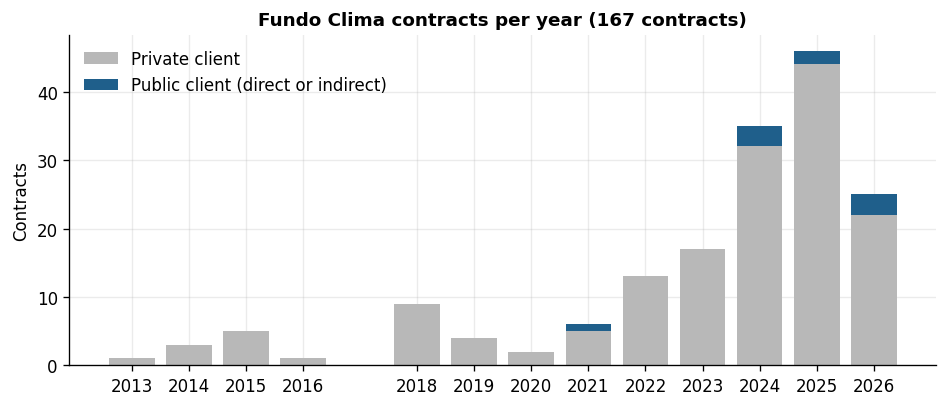

In [17]:
# 6.3 Fundo Clima contracts per year, public vs private client (source filter from the README)
fc_mask = subcredits["instrumento_financeiro"].eq(FUNDO_CLIMA_INSTRUMENT) | subcredits["fonte_de_recurso_desembolsos"].fillna("").str.contains("FUNDO CLIMA")
fc_contract_ids = set(subcredits.loc[fc_mask, "numero_do_contrato"])
fc_rows = subcredits[subcredits["numero_do_contrato"].isin(fc_contract_ids)]
assert len(fc_contract_ids) == 167 and len(fc_rows) == 434
fc_contracts = fc_rows.groupby("numero_do_contrato").agg(year=("contract_year", "min"),
    public=("natureza_do_cliente", lambda s: s.ne("PRIVADA").any()))
fc_by_year = fc_contracts.pivot_table(index="year", columns="public", aggfunc="size", fill_value=0).rename(columns={False: "Private", True: "Public"})
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(fc_by_year.index, fc_by_year["Private"], color=GREY, label="Private client")
ax.bar(fc_by_year.index, fc_by_year["Public"], bottom=fc_by_year["Private"], color=BLUE, label="Public client (direct or indirect)")
ax.set_title("Fundo Clima contracts per year (167 contracts)"); ax.set_ylabel("Contracts"); ax.set_xticks(fc_by_year.index)
ax.legend(frameon=False); fig.tight_layout(); plt.show()

### 6.4 Fit: must-have evidence fields (need `search.yaml`)
Filled share of each must-have after cleaning. `stage_and_date` is the contract date for every row; disbursement stage exists only as a cumulative amount without dates.

In [18]:
must_have = {
    "native_record_id": subcredits["numero_do_contrato"].notna(),
    "recipient (name + CNPJ + nature)": subcredits[["cliente", "cnpj", "natureza_do_cliente"]].notna().all(axis=1) & subcredits["cliente"].ne("SEM NOME"),
    "recipient_geography (valid IBGE code)": subcredits["is_brazilian_municipality"],
    "recipient_geography (valid UF at least)": subcredits["is_brazilian_uf"],
    "funder_or_programme (instrumento_financeiro)": subcredits["instrumento_financeiro"].notna() & subcredits["instrumento_financeiro"].ne("OUTROS"),
    "instrument (modalidade + produto)": subcredits[["modalidade_de_apoio", "produto"]].notna().all(axis=1),
    "amount_with_meaning (contracted + disbursed)": subcredits[["valor_contratado_reais", "valor_desembolsado_reais"]].notna().all(axis=1),
    "stage_and_date (contract date)": subcredits["data_da_contratacao"].notna(),
}
fit_fields = pd.DataFrame({"filled_share": {k: v.mean() for k, v in must_have.items()}})
fit_fields["filled_share"] = (fit_fields["filled_share"] * 100).round(1).astype(str) + "%"
fit_fields

,filled_share
native_record_id,100.0%
recipient (name + CNPJ + nature),100.0%
recipient_geography (valid IBGE code),67.4%
recipient_geography (valid UF at least),89.1%
funder_or_programme (instrumento_financeiro),89.6%
instrument (modalidade + produto),100.0%
amount_with_meaning (contracted + disbursed),100.0%
stage_and_date (contract date),100.0%


### 6.5 Fit: do the 23 annual-report Fundo Clima approvals appear as contracts?
The compile's BNDES rows come from annual-report approval tables (2024–2025). A report row matches a contract when the normalised client name and client type agree, the contract's `PROGRAMA FUNDO CLIMA` subcredits sum to the printed approval (within 1% or R$60k for rounding), and the contract is dated in or after the approval year. A contract can satisfy only one report row; ties go to the closer project description.

In [19]:
DROP_TOKENS = {"S", "A", "SA", "LTDA", "DE", "DO", "DA", "DOS", "DAS", "MUNICIPIO", "ESTADO", "PREFEITURA"}
def normalise_name(name):
    text = unicodedata.normalize("NFKD", re.sub(r"\(.*?\)", " ", str(name)))
    text = "".join(ch for ch in text if not unicodedata.combining(ch)).upper()
    return " ".join(t for t in re.sub(r"[^A-Z0-9]+", " ", text).split() if t not in DROP_TOKENS)
def tokens(text):
    return set(normalise_name(text).split())

TYPE_TO_NATURE = {"municipio": "ADMINISTRAÇÃO PÚBLICA DIRETA - GOVERNO MUNICIPAL", "estado": "ADMINISTRAÇÃO PÚBLICA DIRETA - GOVERNO ESTADUAL",
                  "empresa-privada": "PRIVADA"}
approvals = pd.read_csv(REPORT_APPROVALS_PATH, sep="\t", dtype=str)
assert len(approvals) == 23
approvals["amount"] = approvals["amount"].astype(float)
approvals["approval_year"] = approvals["award_date"].str[:4].astype(int)

fc_candidates = (subcredits[subcredits["numero_do_contrato"].isin(fc_contract_ids)]
    .groupby("numero_do_contrato").agg(cliente=("cliente", "first"), natureza=("natureza_do_cliente", "first"),
                                       year=("contract_year", "min"), descricao=("descricao_do_projeto", "first"))
    .join(contracts[["fundo_clima_contracted", "contracted"]]))
fc_candidates["name_key"] = fc_candidates["cliente"].map(normalise_name)
fc_candidates["fc_value"] = fc_candidates["fundo_clima_contracted"].astype(float)

pairs = []
for _, a in approvals.iterrows():
    tol = max(60_000, 0.01 * a["amount"])
    hits = fc_candidates[(fc_candidates["name_key"] == normalise_name(a["recipient"]))
                         & (fc_candidates["natureza"] == TYPE_TO_NATURE[a["recipient_type"]])
                         & ((fc_candidates["fc_value"] - a["amount"]).abs() <= tol)
                         & (fc_candidates["year"] >= a["approval_year"])]
    for contract, c in hits.iterrows():
        overlap = len(tokens(a["project_name"]) & tokens(c["descricao"])) / max(1, len(tokens(a["project_name"]) | tokens(c["descricao"])))
        pairs.append((a["source_id"], contract, overlap))
pairs = pd.DataFrame(pairs, columns=["source_id", "numero_do_contrato", "description_overlap"]).sort_values("description_overlap", ascending=False)
assigned = pairs.drop_duplicates("numero_do_contrato").drop_duplicates("source_id")

reconciliation = approvals[["source_id", "recipient", "recipient_type", "amount", "approval_year"]].merge(assigned, on="source_id", how="left")
reconciliation = reconciliation.merge(contracts[["first_date", "contracted"]], left_on="numero_do_contrato", right_index=True, how="left")
reconciliation["status"] = np.select(
    [reconciliation["numero_do_contrato"].notna(), reconciliation["source_id"].isin(pairs["source_id"])],
    ["contract found", "candidate taken by a closer report row"], "no matching contract to 31 Jul 2026")
reconciliation["amount_brl_mn"] = (reconciliation["amount"] / 1e6).round(1)
reconciliation["contract_total_brl_mn"] = (reconciliation["contracted"].astype(float) / 1e6).round(1)
display(reconciliation["status"].value_counts().to_frame())
reconciliation[["source_id", "recipient", "amount_brl_mn", "status", "numero_do_contrato", "first_date", "contract_total_brl_mn"]]

,count
status,
no matching contract to 31 Jul 2026,15
contract found,7
candidate taken by a closer report row,1


,source_id,recipient,amount_brl_mn,status,numero_do_contrato,first_date,contract_total_brl_mn
0,bndes_fc_rel_2024_01,Município de Tangará da Serra,41.3,contract found,24902031,2025-09-08,50.8
1,bndes_fc_rel_2024_02,Município de Mogi das Cruzes,44.0,no matching contract to 31 Jul 2026,NaN,NaN,NaN
2,bndes_fc_rel_2024_03,Estado do Espírito Santo,150.0,contract found,24203391,2026-06-16,150.0
3,bndes_fc_rel_2024_04,Estado do Ceará,250.0,contract found,24203191,2025-12-26,622.6
4,bndes_fc_rel_2024_05,Ciclus Ambiental Rio S/A,88.0,no matching contract to 31 Jul 2026,NaN,NaN,NaN
5,bndes_fc_rel_2024_06,Município de Porto Alegre,447.8,no matching contract to 31 Jul 2026,NaN,NaN,NaN
6,bndes_fc_rel_2024_07,Município de Belo Horizonte,317.0,no matching contract to 31 Jul 2026,NaN,NaN,NaN
7,bndes_fc_rel_2024_08,Município de Curitiba,380.0,no matching contract to 31 Jul 2026,NaN,NaN,NaN
8,bndes_fc_rel_2024_09,Estado do Espírito Santo,150.0,candidate taken by a closer report row,NaN,NaN,NaN
9,bndes_fc_rel_2025_01,Estado do Espírito Santo,350.0,no matching contract to 31 Jul 2026,NaN,NaN,NaN


### 6.6 Fit: which BNDES routes have public borrowers used?
Contracts with a municipal or state direct-administration client, by support modality, product and financing instrument. This evidences the domestic-credit and non-repayable pathways for public actors; it is not an eligibility test.

In [20]:
PUBLIC_DIRECT = ["ADMINISTRAÇÃO PÚBLICA DIRETA - GOVERNO MUNICIPAL", "ADMINISTRAÇÃO PÚBLICA DIRETA - GOVERNO ESTADUAL"]
public_rows = subcredits[subcredits["natureza_do_cliente"].isin(PUBLIC_DIRECT)].assign(v=lambda d: d["valor_contratado_reais"].astype(float))
public_rows = public_rows.assign(level=public_rows["natureza_do_cliente"].map({PUBLIC_DIRECT[0]: "Municipal", PUBLIC_DIRECT[1]: "State"}),
                                 period=np.where(public_rows["contract_year"] >= 2020, "2020+", "2002-2019"))
routes = (public_rows.groupby(["level", "instrumento_financeiro_en"])
          .agg(contracts=("numero_do_contrato", "nunique"), contracts_2020_plus=("numero_do_contrato", lambda s: s[public_rows.loc[s.index, "period"].eq("2020+")].nunique()),
               contracted_brl_mn=("v", lambda s: round(s.sum() / 1e6)))
          .sort_values(["level", "contracts"], ascending=[True, False]))
print("municipal borrowers:", public_rows.loc[public_rows["level"].eq("Municipal"), "cnpj"].nunique(),
      "| municipal contracts:", public_rows.loc[public_rows["level"].eq("Municipal"), "numero_do_contrato"].nunique(),
      "| of which 2020+:", public_rows.loc[public_rows["level"].eq("Municipal") & public_rows["period"].eq("2020+"), "numero_do_contrato"].nunique())
routes.groupby(level=0).head(8)

municipal borrowers: 378 | municipal contracts: 528 | of which 2020+: 31


contracts  \
level     instrumento_financeiro_en                                                 
Municipal BNDES PMAT                                                          360   
          BNDES Socio-environmental Fund                                       37   
          Environmental Sanitation and Water Resources                         30   
          PMI                                                                  30   
          Modernization of State, Federal-District and Municipal Pu...         20   
          Other                                                                20   
          Fundo Amazônia                                                        7   
          Fundo Clima Programme                                                 6   
State     BNDES States                                                         43   
          Fundo Amazônia                                                       29   
          Other                                                                27   
          PEF BNDES                                                            25   
          PMAE                                                                 25   
          BNDES Socio-environmental Fund                                       23   
          PROINVESTE                                                           17   
          BNDES Invest Impacto Programme                                       13   

                                                                        contracts_2020_plus  \
level     instrumento_financeiro_en                                                           
Municipal BNDES PMAT                                                                      0   
          BNDES Socio-environmental Fund                                                  0   
          Environmental Sanitation and Water Resources                                    0   
          PMI                                                                             0   
          Modernization of State, Federal-District and Municipal Pu...                   17   
          Other                                                                           3   
          Fundo Amazônia                                                                  0   
          Fundo Clima Programme                                                           6   
State     BNDES States                                                                    0   
          Fundo Amazônia                                                                 11   
          Other                                                                           3   
          PEF BNDES                                                                       0   
          PMAE                                                                            0   
          BNDES Socio-environmental Fund                                                  4   
          PROINVESTE                                                                      0   
          BNDES Invest Impacto Programme                                                 13   

                                                                        contracted_brl_mn  
level     instrumento_financeiro_en                                                        
Municipal BNDES PMAT                                                                 1906  
          BNDES Socio-environmental Fund                                              119  
          Environmental Sanitation and Water Resources                               1143  
          PMI                                                                        1285  
          Modernization of State, Federal-District and Municipal Pu...               1070  
          Other                                                                      1157  
          Fundo Amazônia                                                               15  
  

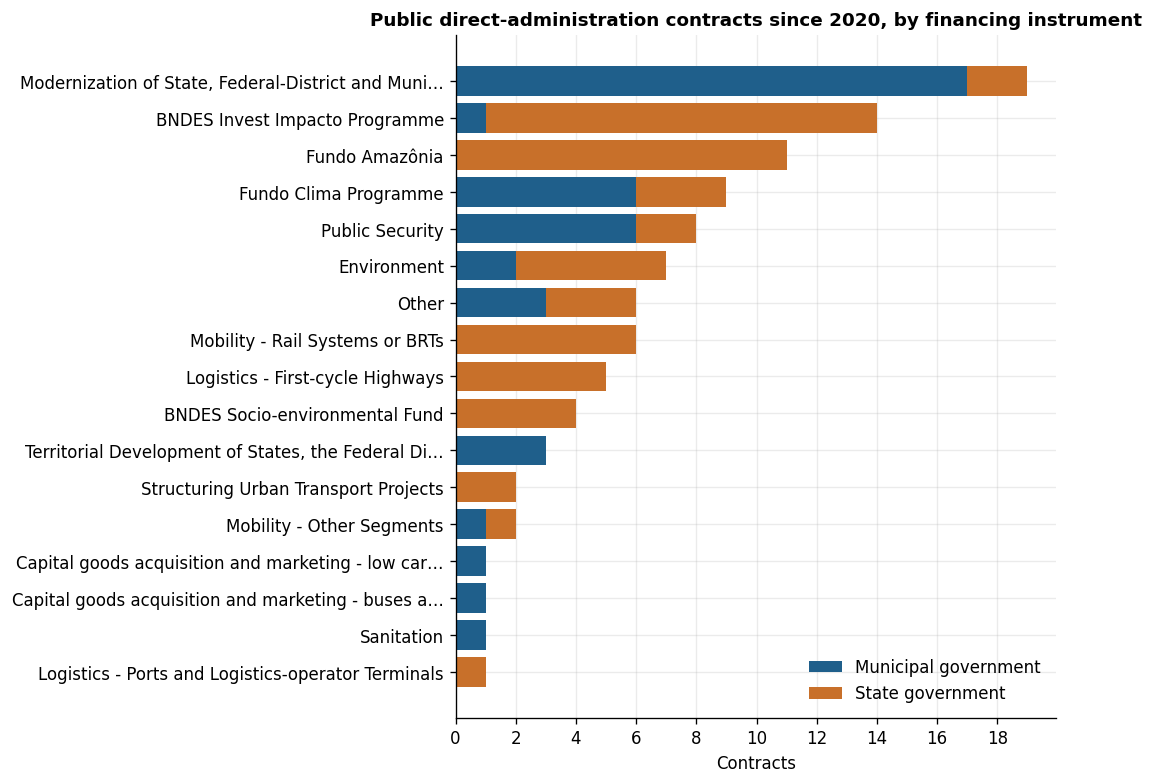

In [21]:
# 6.7 Current routes: public direct-administration contracts since 2020 by financing instrument
recent = (public_rows[public_rows["period"].eq("2020+")]
          .groupby(["instrumento_financeiro_en", "level"])["numero_do_contrato"].nunique().unstack(fill_value=0))
recent = recent.assign(total=recent.sum(axis=1)).sort_values("total").drop(columns="total")
fig, ax = plt.subplots(figsize=(9, 0.32 * len(recent) + 1.2))
short_labels = [t if len(t) <= 50 else t[:49].rstrip() + "…" for t in recent.index]
ax.barh(short_labels, recent.get("Municipal", 0), color=BLUE, label="Municipal government")
ax.barh(short_labels, recent.get("State", 0), left=recent.get("Municipal", 0), color=ORANGE, label="State government")
ax.set_title("Public direct-administration contracts since 2020, by financing instrument"); ax.set_xlabel("Contracts")
ax.xaxis.set_major_locator(mtick.MaxNLocator(integer=True)); ax.legend(frameon=False, loc="lower right"); fig.tight_layout(); plt.show()

## 7. Findings

Extraction reproduced the README profile. The raw file matches the publisher's MD5, the live header has 34 fields, and every figure asserted in §4 held: 23,815 subcredits, 8,388 contracts, both modality counts, the status split including 268 unknowns, the Fundo Clima filter (167 contracts, 434 rows), and the four annual-report spot-checks where the Fundo Clima component differs from the contract total. The export is one subcredit table in `data/` with English column names; translated fields carry English values beside the Portuguese source values (`_pt`), and amounts are kept as exact decimal text. English values come from a committed lookup of 7,723 translations (6,594 project descriptions and 1,129 categorical values), which the notebook checks is complete in both directions.

One README figure was wrong and has been corrected there. Rows without a usable municipality number 7,766, not 5,619: besides 2,599 `IE` rows, 5,167 rows in Brazilian UFs carry code `0` or `9999999` (labelled `SEM MUNICÍPIO` or `DIVERSOS`). The earlier count missed the `9999999` rows. Valid municipality codes therefore cover 16,049 rows (67.4%); 89.1% carry a Brazilian UF. The identical-row wording was also tightened: 654 rows fall in 277 identical groups, of which 377 are extra copies.

Fit against the need is conditional-pass. Every must-have field exists for every row, with two gaps: geography reaches municipality level on two rows in three, and 10.4% of rows name the instrument only as `OUTROS`. Of the 23 Fundo Clima approvals already in the compile, 7 appear as contracts by 31 July 2026 (Tangará da Serra, Espírito Santo resilience, Ceará, Fortaleza, Acre, Gerdau, B.O. Paper), matched on client, type and the Fundo Clima component. The other 16 have no matching record in this resource and period; that includes the second Espírito Santo row, whose R$150 million matched only the resilience contract. An approval is not a contract, and an unmatched approval may still be contracted later, under another client such as a transit operator, or through the automatic-operations resource, none of which this cell tests.

Municipal direct borrowing is mostly historical. 378 municipal governments hold 528 contracts, but only 31 are dated 2020 or later, led by public-administration modernisation (17) and Fundo Clima (6); the 360 PMAT contracts all predate 2020. State governments since 2020 used Invest Impacto (13) and Fundo Amazônia (11). The table therefore evidences which BNDES routes public actors have used, not whether a route is open now.

Open decision: the export exceeds the single-digit-MB guidance for committed `data/` files; see the size printed in §5.